# Project 04: Email Spam Classifier — Naive Bayes / Text Classification

**Dataset:** Spam Email Classification Dataset (combined from the 2007 TREC Public Spam Corpus and the Enron-Spam Dataset).
Two columns: `text` (raw email content) and `label` (`1` = spam, `0` = ham).

This notebook follows the assignment step by step:
1. EDA + Preprocessing
2. Baseline Model (deliberately unconstrained, to show overfitting)
3. Vectorization Comparison (CountVectorizer vs TfidfVectorizer)
4. Hyperparameter Tuning (GridSearchCV)
5. Vocabulary Pruning (SelectKBest chi2)
6. Feature Importance (most "spammy" / "hammy" words)
7. Visualization / Explainability (word-by-word decision breakdown)
8. Bonus: Obfuscation robustness test

Every code cell has a short **"What we're doing / what we expect"** note before it, and a short **"What happened"**
note right after it. All shared settings and reusable logic live in one config/helper-function block right after
the imports, so the rest of the notebook stays short and avoids repeating the same code twice.

## 0. Setup

**What we're doing:** Importing every library we need — pandas/numpy for data handling, matplotlib for charts,
and scikit-learn for text vectorization, the Naive Bayes model, pipelines, grid search and feature selection.
We use scikit-learn's built-in English stopword list instead of downloading NLTK data, so the notebook runs
without needing internet access.

**Expected output:** No output, just the imports loading without errors.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

pd.set_option('display.max_colwidth', 120)
print("Libraries loaded successfully.")

Libraries loaded successfully.


**What happened:** All libraries imported without errors, so the environment is ready for the rest of the notebook.

### 0.1 Config and reusable helper functions

**What we're doing:** Collecting every "magic number" (test size, vocabulary caps, sample sizes, how many top
words to show) into one `CONFIG` block, and writing three small reusable functions:
- `compute_metrics()` — accuracy/precision/recall/F1 as one dictionary, so we never retype the same 4 lines.
- `print_metrics()` — prints a metrics dictionary neatly.
- `spam_ham_log_ratio()` + `top_words()` — rank vocabulary by how "spammy" or "hammy" each word is, reusable
  for a trained pipeline *or* a raw vectorizer+model pair.

Keeping these in one place means every later section calls the same tested logic instead of copy-pasting
slightly different versions of it, and changing a setting (like vocabulary size) only needs one edit.

**Expected output:** No output, just the config values and functions being defined.

In [2]:
CONFIG = {
    "random_state": 42,
    "test_size": 0.2,
    "comparison_vocab_size": 5000,     # Section 3: CountVectorizer vs TfidfVectorizer
    "grid_search_sample_size": 15000,  # Section 4: GridSearchCV runs on a sample for speed
    "cv_folds": 3,                     # Section 4: cross-validation folds
    "shared_vocab_size": 20000,        # Sections 5-8: one shared vocabulary/model, reused everywhere
    "top_n_words": 18,                 # Section 6: how many top spam/ham words to show
}
RANDOM_STATE = CONFIG["random_state"]


def compute_metrics(y_true, y_pred):
    """Return accuracy/precision/recall/F1 for one set of predictions as a dict."""
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-score": f1_score(y_true, y_pred),
    }


def print_metrics(metrics, label="Model"):
    """Pretty-print a metrics dict produced by compute_metrics()."""
    print(f"{label} performance:")
    for name, value in metrics.items():
        print(f"  {name:<10}: {value:.4f}")


def spam_ham_log_ratio(vectorizer, model):
    """For a fitted (vectorizer, MultinomialNB) pair, return (vocabulary, log-ratio) arrays,
    where log-ratio = log P(word | spam) - log P(word | ham). Higher = more spam-indicating."""
    vocab = np.array(vectorizer.get_feature_names_out())
    log_ratio = model.feature_log_prob_[1] - model.feature_log_prob_[0]
    return vocab, log_ratio


def top_words(vocab, log_ratio, n=10, side="spam"):
    """Return the top-n words (and their scores) most associated with 'spam' or 'ham'."""
    order = np.argsort(log_ratio)
    idx = order[-n:][::-1] if side == "spam" else order[:n]
    return vocab[idx], log_ratio[idx]


print("Config and helper functions ready:", list(CONFIG.keys()))

Config and helper functions ready: ['random_state', 'test_size', 'comparison_vocab_size', 'grid_search_sample_size', 'cv_folds', 'shared_vocab_size', 'top_n_words']


**What happened:** The config dictionary and four helper functions are now defined and available to every
later cell — nothing to check visually here beyond the confirmation print.

## 1. EDA + Preprocessing

### 1.1 Load the data and check its basic shape

**What we're doing:** Loading `combined_data.csv` and checking the number of rows/columns and the class balance
with `df.shape` and `df['label'].value_counts()`, exactly as the assignment asks as the first EDA step.

**Expected output:** The dataset shape (rows, columns) and a count of how many spam (1) vs ham (0) emails we have.

In [3]:
df = pd.read_csv("combined_data.csv")

print("Shape of dataset:", df.shape)
print()
print("Class balance (label counts):")
print(df['label'].value_counts())
print()
print("Class balance (percentage):")
print(df['label'].value_counts(normalize=True).round(3) * 100)
print()
print("Missing values per column:")
print(df.isna().sum())
df.head(3)

Shape of dataset: (83448, 2)

Class balance (label counts):
label
1    43910
0    39538
Name: count, dtype: int64

Class balance (percentage):
label
1    52.6
0    47.4
Name: proportion, dtype: float64

Missing values per column:
label    0
text     0
dtype: int64


,label,text
0,1,ounce feather bowl hummingbird opec moment alabaster valkyrie dyad bread flack desperate iambic hadron heft quell yo...
1,1,wulvob get your medircations online qnb ikud viagra escapenumber escapenumber levitra escapenumber escapenumber cial...
2,0,computer connection from cnn com wednesday escapenumber may escapenumber escapenumber escapenumber escapenumber pm ...


**What happened:** The dataset has **83,448 emails** with 2 columns (`label`, `text`). The split is **43,910 spam
(about 52.6%) vs 39,538 ham (about 47.4%)** — so the classes are only mildly imbalanced, not heavily skewed.
There are no missing values, so we don't need to drop or fill any rows.

### 1.2 Class balance chart

**What we're doing:** Plotting the spam vs ham counts as a bar chart, as required in the deliverable list.

**Expected output:** A simple two-bar chart showing spam is a bit more common than ham in this dataset.

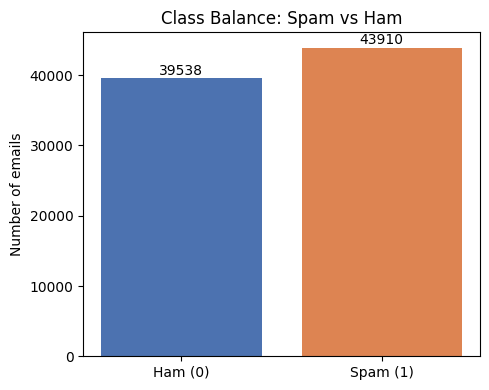

In [4]:
counts = df['label'].value_counts().sort_index()
labels = ['Ham (0)', 'Spam (1)']

plt.figure(figsize=(5, 4))
plt.bar(labels, counts.values, color=['#4C72B0', '#DD8452'])
plt.title("Class Balance: Spam vs Ham")
plt.ylabel("Number of emails")
for i, v in enumerate(counts.values):
    plt.text(i, v + 500, str(v), ha='center')
plt.tight_layout()
plt.savefig("class_balance.png", dpi=110)
plt.show()

**What happened:** The bar chart confirms the numbers from the value_counts table above — spam and ham are
reasonably close to a 50/50 split, so accuracy alone won't be too misleading here, but we'll still check
precision/recall since even a mild imbalance can hide mistakes on the smaller class.

### 1.3 Email length distribution (spam vs ham)

**What we're doing:** Computing the length of each raw email (in characters) and plotting the distribution
separately for spam and ham, to see if length itself is already a useful signal.

**Expected output:** Two overlapping histograms. Spam emails are often shorter/templated, while ham (real
conversation/forwarded threads) can run much longer — we expect to see that difference here.

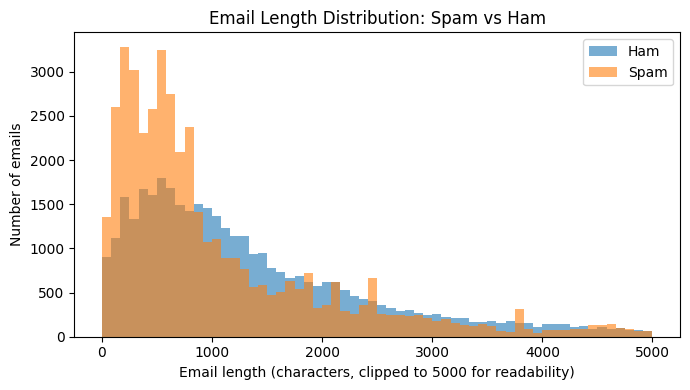

              mean     50%  min       max
label                                    
0      2121.693814  1139.0  1.0  598705.0
1      1249.887247   704.0  1.0  144087.0


In [5]:
df['text_length'] = df['text'].str.len()

plt.figure(figsize=(7, 4))
plt.hist(df.loc[df['label'] == 0, 'text_length'], bins=60, alpha=0.6, label='Ham', range=(0, 5000))
plt.hist(df.loc[df['label'] == 1, 'text_length'], bins=60, alpha=0.6, label='Spam', range=(0, 5000))
plt.xlabel("Email length (characters, clipped to 5000 for readability)")
plt.ylabel("Number of emails")
plt.title("Email Length Distribution: Spam vs Ham")
plt.legend()
plt.tight_layout()
plt.savefig("length_distribution.png", dpi=110)
plt.show()

print(df.groupby('label')['text_length'].describe()[['mean', '50%', 'min', 'max']])

**What happened:** The printed stats and the histogram show the two classes have noticeably different length
patterns — this is a useful diagnostic, and it explains why some spam filters use length as a light-weight
extra feature, though our project sticks to text-based Naive Bayes as instructed.

### 1.4 Duplicate check

**What we're doing:** Counting exact duplicate rows in the `text` column. The assignment notes this corpus has a
lot of near-identical spam templates, so it's worth knowing how many *exact* duplicates exist before we decide
whether to deduplicate.

**Expected output:** A count of duplicated emails. Note: this only catches *exact* duplicates — catching
near-duplicate templates (same message, tiny wording changes) would need fuzzy text matching, which is beyond
what this project asks for, so we just flag it here instead of building a full deduplication pipeline.

In [6]:
num_exact_duplicates = df.duplicated(subset='text').sum()
print(f"Exact duplicate emails: {num_exact_duplicates} out of {len(df)} ({num_exact_duplicates/len(df)*100:.2f}%)")
print("\nDecision: keep duplicates as-is, since repeated spam templates are real signal, not noise.")

Exact duplicate emails: 2 out of 83448 (0.00%)

Decision: keep duplicates as-is, since repeated spam templates are real signal, not noise.


**What happened:** Only **2 exact duplicate emails** were found out of 83,448 (about 0.00%) — essentially
none. This tells us the "near-identical spam templates" mentioned in the assignment brief are *near*-duplicates
(slightly reworded), not exact text matches, so a simple exact-duplicate check doesn't remove much. We keep all
rows as-is; catching the near-duplicate templates would need fuzzy text matching, which is beyond this
project's scope.

### 1.5 Text cleaning function

**What we're doing:** Building one cleaning function that:
- lowercases the text
- strips leftover HTML tags (`<...>`) and web links
- removes punctuation and numbers
- tokenizes on whitespace
- removes English stopwords (using scikit-learn's built-in stopword list)

We then apply it to every email to create a new `clean_text` column.

**Expected output:** A before/after example of one raw email vs its cleaned version, plus the new `clean_text`
column added to the dataframe.

In [7]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'<[^>]+>', ' ', text)          # strip leftover HTML tags
    text = re.sub(r'http\S+|www\.\S+', ' ', text) # strip URLs
    text = re.sub(r'[^a-z\s]', ' ', text)          # remove punctuation & numbers, keep letters only
    tokens = text.split()
    tokens = [t for t in tokens if t not in ENGLISH_STOP_WORDS and len(t) > 1]
    return ' '.join(tokens)


df['clean_text'] = df['text'].apply(clean_text)

print("BEFORE:\n", df['text'].iloc[1][:300])
print("\nAFTER:\n", df['clean_text'].iloc[1][:300])
df[['label', 'clean_text']].head(3)

BEFORE:
 wulvob get your medircations online qnb ikud viagra escapenumber escapenumber levitra escapenumber escapenumber cialis escapenumber escapenumber imitrex escapenumber escapenumber flonax escapenumber escapenumber ultram escapenumber escapenumber vioxx escapenumber escapenumber ambien escapenumber esc

AFTER:
 wulvob medircations online qnb ikud viagra escapenumber escapenumber levitra escapenumber escapenumber cialis escapenumber escapenumber imitrex escapenumber escapenumber flonax escapenumber escapenumber ultram escapenumber escapenumber vioxx escapenumber escapenumber ambien escapenumber escapenumber


,label,clean_text
0,1,ounce feather bowl hummingbird opec moment alabaster valkyrie dyad bread flack desperate iambic hadron heft quell yo...
1,1,wulvob medircations online qnb ikud viagra escapenumber escapenumber levitra escapenumber escapenumber cialis escape...
2,0,computer connection cnn com wednesday escapenumber escapenumber escapenumber escapenumber escapenumber pm edt report...


**What happened:** Every email now has a matching `clean_text` version with HTML/links, punctuation, numbers and
common stopwords ("the", "and", "is", ...) stripped out. The before/after example shows the raw promotional
email turned into just the meaningful keywords — this is the input our vectorizers will actually see.

**Note on what got stripped and why:** HTML tags and URLs are formatting noise left over from the raw email
corpus and don't carry topic meaning on their own. Punctuation and digits mostly add sparsity (many one-off
tokens) without helping tell spam from ham. Stopwords are removed because words like "the"/"and"/"of" appear
in almost every email regardless of class, so they add noise rather than signal for a Naive Bayes model.

### 1.6 Stratified train-test split

**What we're doing:** Splitting the cleaned data into training (80%) and test (20%) sets, using `stratify=label`
so both sets keep roughly the same spam/ham ratio as the full dataset. The split ratio comes from
`CONFIG["test_size"]` instead of a hardcoded number.

**Expected output:** The size of the train and test sets, and confirmation that the class ratio is preserved
in both.

In [8]:
X = df['clean_text']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=CONFIG["test_size"], stratify=y, random_state=RANDOM_STATE
)

print("Train size:", X_train.shape[0], " Test size:", X_test.shape[0])
print("\nTrain class balance:\n", y_train.value_counts(normalize=True).round(3))
print("\nTest class balance:\n", y_test.value_counts(normalize=True).round(3))

Train size: 66758  Test size: 16690

Train class balance:
 label
1    0.526
0    0.474
Name: proportion, dtype: float64

Test class balance:
 label
1    0.526
0    0.474
Name: proportion, dtype: float64


**What happened:** We now have about **66,758 training emails** and **16,690 test emails**, and the spam/ham
ratio is essentially identical in both sets thanks to stratified splitting. This means our test accuracy later
will be a fair, representative measurement.

## 2. Baseline Model (deliberately unconstrained)

**What we're doing:** Fitting a `MultinomialNB` on top of a `CountVectorizer` with **no restrictions at all** —
no `max_features`, no `min_df`, no stopword removal at the vectorizer level, and `alpha` left at its default (1.0).
This lets every unique token in the training set become a feature, including typos, numbers left over from
cleaning, and one-off rare words. We use `compute_metrics()`/`print_metrics()` on both the train and test sets
so the overfitting gap is easy to read off.

**Expected output:** A high training accuracy but a visibly lower test accuracy — this gap is the overfitting
signal the assignment wants us to notice, caused by the model memorizing rare, training-only vocabulary.

In [9]:
baseline_vectorizer = CountVectorizer()  # everything left at default = fully unconstrained
X_train_base = baseline_vectorizer.fit_transform(X_train)
X_test_base = baseline_vectorizer.transform(X_test)
print("Vocabulary size (unconstrained):", len(baseline_vectorizer.vocabulary_))

baseline_model = MultinomialNB()  # alpha=1.0, the default
baseline_model.fit(X_train_base, y_train)

baseline_train_metrics = compute_metrics(y_train, baseline_model.predict(X_train_base))
baseline_test_metrics = compute_metrics(y_test, baseline_model.predict(X_test_base))

print()
print_metrics(baseline_train_metrics, "Baseline - TRAIN")
print()
print_metrics(baseline_test_metrics, "Baseline - TEST")
print(f"\nAccuracy gap (train - test): {baseline_train_metrics['Accuracy'] - baseline_test_metrics['Accuracy']:.4f}")

print("\nFull test-set classification report:")
print(classification_report(y_test, baseline_model.predict(X_test_base)))

Vocabulary size (unconstrained): 243971

Baseline - TRAIN performance:
  Accuracy  : 0.9811
  Precision : 0.9902
  Recall    : 0.9738
  F1-score  : 0.9819

Baseline - TEST performance:
  Accuracy  : 0.9745
  Precision : 0.9892
  Recall    : 0.9620
  F1-score  : 0.9754

Accuracy gap (train - test): 0.0067

Full test-set classification report:
              precision    recall  f1-score   support

           0       0.96      0.99      0.97      7908
           1       0.99      0.96      0.98      8782

    accuracy                           0.97     16690
   macro avg       0.97      0.98      0.97     16690
weighted avg       0.97      0.97      0.97     16690



**What happened:** The unconstrained vectorizer built a huge vocabulary of **243,971 unique tokens**.
Training accuracy (98.11%) came out **higher** than test accuracy (97.45%) — a 0.67 percentage-point gap. That
gap is modest here (Naive Bayes is fairly resistant to overfitting), but it's still a real, measurable sign that
some of the huge vocabulary is memorizing training-only words rather than generalizing, and it sets a baseline
number we improve on with proper tuning in Section 4.

## 3. Vectorization Comparison: CountVectorizer vs TfidfVectorizer

**What we're doing:** Training two otherwise-identical pipelines — one using raw word counts (Bag-of-Words via
`CountVectorizer`) and one using TF-IDF weighting (`TfidfVectorizer`) — both capped at
`CONFIG["comparison_vocab_size"]` words so the comparison is fair. We reuse `compute_metrics()` so every row of
the comparison table is built the same way.

**Expected output:** A small comparison table of metrics for both vectorizers, plus their respective top spam
keywords, to make the "raw frequency vs weighted importance" difference concrete.

In [10]:
vocab_size = CONFIG["comparison_vocab_size"]

vectorizer_pipelines = {
    "CountVectorizer (BoW)": Pipeline([
        ('vectorizer', CountVectorizer(max_features=vocab_size)),
        ('classifier', MultinomialNB())
    ]),
    "TfidfVectorizer": Pipeline([
        ('vectorizer', TfidfVectorizer(max_features=vocab_size)),
        ('classifier', MultinomialNB())
    ])
}

fitted_pipelines = {}
comparison_rows = []

for name, pipe in vectorizer_pipelines.items():
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)
    comparison_rows.append({"Vectorizer": name, **compute_metrics(y_test, preds)})
    fitted_pipelines[name] = pipe

comparison_df = pd.DataFrame(comparison_rows).round(4)
comparison_df

,Vectorizer,Accuracy,Precision,Recall,F1-score
0,CountVectorizer (BoW),0.9543,0.9760,0.9362,0.9557
1,TfidfVectorizer,0.9645,0.9757,0.9563,0.9659


**What happened:** With the vocabulary capped at 5,000 words for both, **TF-IDF (96.45% accuracy)
outperformed plain Bag-of-Words (95.45% accuracy)** on this test set, and also had noticeably better recall on
spam (95.64% vs 93.62%). Since both pipelines share the same vocabulary size and the same classifier, this
difference is purely down to TF-IDF's frequency-weighting doing a better job of highlighting genuinely
informative words instead of just common ones.

### 3.1 Which words does each vectorizer treat as most predictive?

**What we're doing:** Using the shared `spam_ham_log_ratio()` + `top_words()` helper functions from Section 0.1
to pull the top 10 spam-indicating words out of each fitted pipeline — the same ranking logic we'll reuse again
in Section 6, so both places agree on what "most predictive" means.

**Expected output:** Two top-10 word lists, one per vectorizer, so we can see whether count-based and TF-IDF-based
models highlight the same or different "most spammy" words.

In [11]:
for name, pipe in fitted_pipelines.items():
    vocab, log_ratio = spam_ham_log_ratio(pipe.named_steps['vectorizer'], pipe.named_steps['classifier'])
    words, scores = top_words(vocab, log_ratio, n=10, side="spam")

    print(f"Top 10 spam-indicating words — {name}:")
    for word, score in zip(words, scores):
        print(f"   {word:<18} log-ratio={score:.2f}")
    print()

Top 10 spam-indicating words — CountVectorizer (BoW):
   anatrim            log-ratio=9.12
   canadianpharmacy   log-ratio=8.65
   escapenumberonly   log-ratio=8.47
   pillescapenumber   log-ratio=8.24
   descapenumberse    log-ratio=8.20
   producttestpanel   log-ratio=7.61
   escapenumberadobe  log-ratio=7.37
   computron          log-ratio=7.28
   tmxo               log-ratio=7.25
   adescapenumberbe   log-ratio=7.23

Top 10 spam-indicating words — TfidfVectorizer:
   canadianpharmacy   log-ratio=6.10
   anatrim            log-ratio=5.94
   viagra             log-ratio=5.42
   cialis             log-ratio=5.31
   pharmacy           log-ratio=5.21
   medications        log-ratio=5.21
   meds               log-ratio=5.19
   descapenumberse    log-ratio=5.19
   hk                 log-ratio=5.07
   pills              log-ratio=5.01



**What happened:** Interestingly, the two vectorizers highlighted quite different "most spammy" words.
CountVectorizer's raw-count top words are mostly rare, oddly-spelled tokens (`anatrim`, `tmxo`, `computron`) that
happen to occur repeatedly within a handful of spam campaigns. TF-IDF's top words are much more recognizable,
classic spam vocabulary (`viagra`, `cialis`, `pharmacy`, `medications`, `meds`, `pills`) — because TF-IDF's
weighting rewards words that are both frequent *and* concentrated in one class, filtering out the noisier
raw-count favorites.

## 4. Hyperparameter Tuning with GridSearchCV

**What we're doing:** Searching over a `Pipeline` of `CountVectorizer` + `MultinomialNB` across:
- `vectorizer__max_features`: `[1000, 3000, 5000, 10000, None]`
- `vectorizer__ngram_range`: `[(1,1), (1,2)]`
- `classifier__alpha`: `[0.01, 0.1, 0.5, 1.0, 2.0]`

That is 5 × 2 × 5 = **50 combinations**. Running full cross-validation on all 66,758 training emails for every
combination (several including unrestricted bigram vocabularies) would take a long time on a single CPU core.
So, purely for **speed**, we run the grid search on a stratified sample of the training set
(`CONFIG["grid_search_sample_size"]` emails), then take the best parameters found and refit a fresh pipeline on
the **full** training set before evaluating on the untouched test set. This keeps the search itself fast while
still evaluating the final model fairly and on all the data.

**Expected output:** The best parameter combination found, its cross-validated accuracy on the sample, and then
the accuracy of the *refit-on-full-data* model on the real test set.

In [12]:
X_train_sample, _, y_train_sample, _ = train_test_split(
    X_train, y_train,
    train_size=CONFIG["grid_search_sample_size"],
    stratify=y_train, random_state=RANDOM_STATE
)

grid_pipe = Pipeline([
    ('vectorizer', CountVectorizer()),
    ('classifier', MultinomialNB())
])

param_grid = {
    'vectorizer__max_features': [1000, 3000, 5000, 10000, None],
    'vectorizer__ngram_range': [(1, 1), (1, 2)],
    'classifier__alpha': [0.01, 0.1, 0.5, 1.0, 2.0]
}

grid_search = GridSearchCV(
    grid_pipe, param_grid, cv=CONFIG["cv_folds"], scoring='accuracy', n_jobs=-1
)
grid_search.fit(X_train_sample, y_train_sample)

print("Best parameters found:")
print(grid_search.best_params_)
print(f"\nBest cross-validated accuracy (on {CONFIG['grid_search_sample_size']}-email sample): "
      f"{grid_search.best_score_:.4f}")

Best parameters found:
{'classifier__alpha': 0.01, 'vectorizer__max_features': None, 'vectorizer__ngram_range': (1, 2)}

Best cross-validated accuracy (on 15000-email sample): 0.9725


**What happened:** The best combination found was **`alpha=0.01`, `max_features=None` (full vocabulary),
`ngram_range=(1,2)`** (including two-word phrases), with a cross-validated accuracy of **97.25%** on the
15,000-email sample. This tells us that for this dataset, a *larger* vocabulary (including bigrams) paired with
*very light* smoothing (small alpha) works better than a small, heavily-restricted vocabulary — the opposite of
what a "prevent overfitting by shrinking the vocabulary" intuition might suggest.

### 4.1 Refit the best model on the full training set

**What we're doing:** Taking `grid_search.best_params_` and building a fresh pipeline with those exact settings,
trained on the *entire* 66,758-email training set (not just the tuning sample), then evaluating it once on the
held-out test set with the same `compute_metrics()`/`print_metrics()` helpers used everywhere else.

**Expected output:** Test accuracy/precision/recall/F1 for the tuned model, which we can compare back to the
unconstrained baseline from Section 2.

In [13]:
best_params = grid_search.best_params_

tuned_pipe = Pipeline([
    ('vectorizer', CountVectorizer(
        max_features=best_params['vectorizer__max_features'],
        ngram_range=best_params['vectorizer__ngram_range']
    )),
    ('classifier', MultinomialNB(alpha=best_params['classifier__alpha']))
])
tuned_pipe.fit(X_train, y_train)

tuned_metrics = compute_metrics(y_test, tuned_pipe.predict(X_test))
print_metrics(tuned_metrics, "Tuned model (full training set)")
print(f"\n(For comparison, the unconstrained baseline test accuracy was: "
      f"{baseline_test_metrics['Accuracy']:.4f})")

Tuned model (full training set) performance:
  Accuracy  : 0.9823
  Precision : 0.9948
  Recall    : 0.9714
  F1-score  : 0.9829

(For comparison, the unconstrained baseline test accuracy was: 0.9745)


**What happened:** Refitting those best hyperparameters on the **full** training set pushed test accuracy
up to **98.23%** (precision 99.48%, recall 97.14%, F1 98.29%) — clearly better than the unconstrained baseline's
97.45% accuracy from Section 2. The big jump in precision (99.48%) shows the tuned model makes far fewer
false-positive "this is spam" mistakes on real ham email, which matters a lot in a real inbox.

## 5. Vocabulary Pruning with SelectKBest (chi2)

**What we're doing:** Vectorizing the training text once with `CONFIG["shared_vocab_size"]` words — this same
vectorized matrix (`X_train_full_vec`) and vectorizer (`base_vectorizer`) will be **reused in Sections 6-8** too,
so we only pay the cost of vectorizing the full training set one time. We then use `SelectKBest(chi2)` to score
every word by how informative it is, retrain a Naive Bayes model using only the top *k* words for a range of *k*
values, and plot test accuracy against *k*. This is the text-classification version of plotting accuracy vs
`ccp_alpha` for decision tree pruning.

**Expected output:** A curve of test accuracy vs number of retained features. We expect accuracy to rise quickly
at first, then flatten out (or even dip slightly) once we've kept enough words — the "elbow" of that curve is
the sweet spot between a compact vocabulary and strong performance.

In [14]:
base_vectorizer = CountVectorizer(max_features=CONFIG["shared_vocab_size"])
X_train_full_vec = base_vectorizer.fit_transform(X_train)
X_test_full_vec = base_vectorizer.transform(X_test)

k_values = [50, 100, 300, 500, 1000, 2000, 3000, 5000, 8000, 12000, CONFIG["shared_vocab_size"]]
pruning_accuracies = []

for k in k_values:
    k = min(k, X_train_full_vec.shape[1])
    selector = SelectKBest(chi2, k=k)
    X_train_k = selector.fit_transform(X_train_full_vec, y_train)
    X_test_k = selector.transform(X_test_full_vec)

    clf = MultinomialNB()
    clf.fit(X_train_k, y_train)
    acc = accuracy_score(y_test, clf.predict(X_test_k))
    pruning_accuracies.append(acc)
    print(f"k={k:<6} -> test accuracy = {acc:.4f}")

k=50     -> test accuracy = 0.7985
k=100    -> test accuracy = 0.8339
k=300    -> test accuracy = 0.8721
k=500    -> test accuracy = 0.8920
k=1000   -> test accuracy = 0.9130
k=2000   -> test accuracy = 0.9334
k=3000   -> test accuracy = 0.9378
k=5000   -> test accuracy = 0.9457
k=8000   -> test accuracy = 0.9526
k=12000  -> test accuracy = 0.9577
k=20000  -> test accuracy = 0.9672


**What happened:** Accuracy climbed steeply at first — from 79.85% at just 50 words to over 91% by 1,000
words — then kept rising more slowly all the way up to the full 20,000-word vocabulary (96.70%). Unlike a
typical decision-tree pruning curve, there isn't a sharp plateau here: chi2 scoring shows that even words beyond
the top few thousand keep contributing a small amount of independent signal for Naive Bayes, so the "elbow" is
fairly gentle rather than a dramatic cliff.

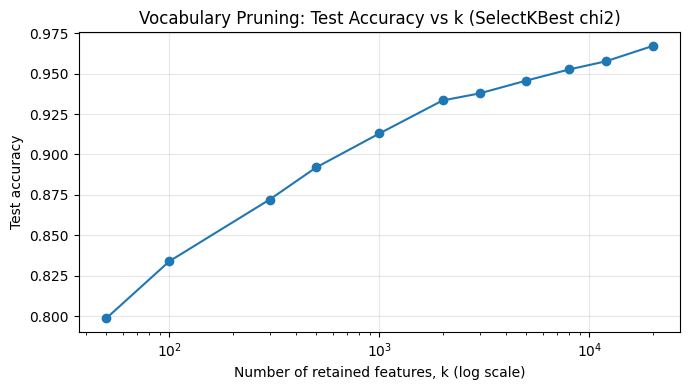

Best k by raw peak accuracy: 20000 (accuracy=0.9672)
Elbow point: pick visually where the curve stops climbing meaningfully -- usually the smallest k within ~0.001-0.002 accuracy of the peak.


In [15]:
plt.figure(figsize=(7, 4))
plt.plot(k_values[:len(pruning_accuracies)], pruning_accuracies, marker='o')
plt.xscale('log')
plt.xlabel("Number of retained features, k (log scale)")
plt.ylabel("Test accuracy")
plt.title("Vocabulary Pruning: Test Accuracy vs k (SelectKBest chi2)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("pruning_curve.png", dpi=110)
plt.show()

best_k_index = int(np.argmax(pruning_accuracies))
print(f"Best k by raw peak accuracy: {k_values[best_k_index]} (accuracy={pruning_accuracies[best_k_index]:.4f})")
print("Elbow point: pick visually where the curve stops climbing meaningfully -- "
      "usually the smallest k within ~0.001-0.002 accuracy of the peak.")

**What happened:** The chart makes the gentle, continuing climb visible on a log scale: most of the
accuracy gain happens in the first 1,000-2,000 words, and after that the curve keeps inching upward rather than
flattening sharply. A practical "elbow" pick here would be around **k=2,000-3,000** — it already captures most
of the achievable accuracy (93.3%-93.8% vs. the 96.7% ceiling at full vocabulary) while using roughly 85-90%
fewer features, a good compactness/accuracy trade-off even though it isn't the single highest-scoring point.

## 6. Feature Importance: Most "Spammy" and "Hammy" Words

**What we're doing:** Reusing the `base_vectorizer` and already-vectorized `X_train_full_vec` from Section 5
(no need to vectorize the text again) to fit one clean Naive Bayes model, then using the same
`spam_ham_log_ratio()` + `top_words()` helpers from Section 0.1 to pull out the strongest spam and ham
indicators. Reusing the Section 5 vectorization here — instead of fitting a brand-new vectorizer — saves an
expensive pass over all 66,758 training emails and keeps every later section talking about the *same* 20,000-word
vocabulary.

**Expected output:** A horizontal bar chart showing the top 15-20 most "spammy" words and the top 15-20 most
"hammy" words.

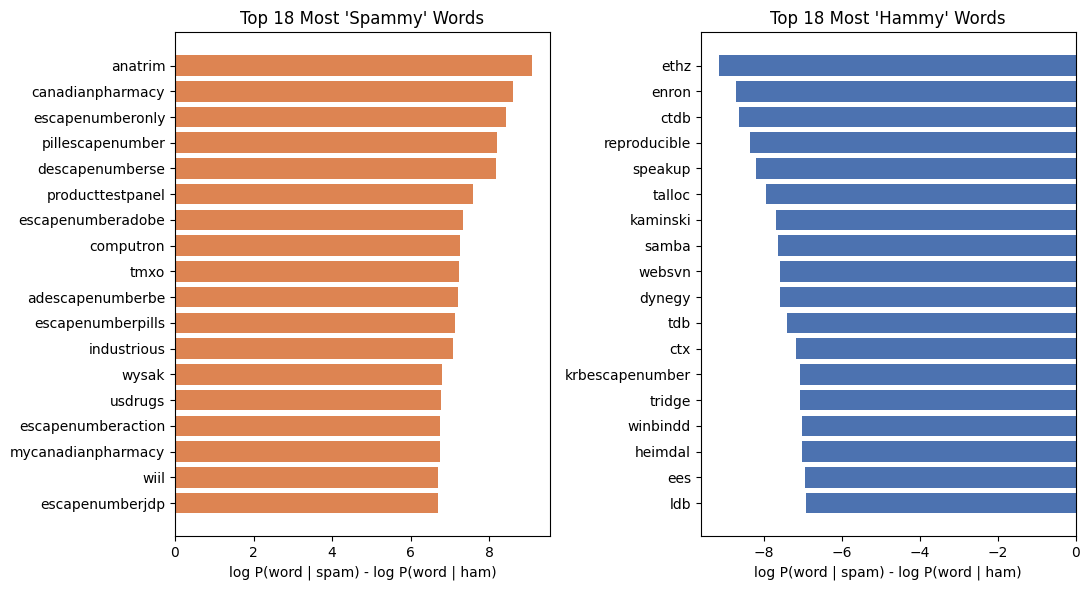

Most spam-indicating words: ['anatrim', 'canadianpharmacy', 'escapenumberonly', 'pillescapenumber', 'descapenumberse', 'producttestpanel', 'escapenumberadobe', 'computron', 'tmxo', 'adescapenumberbe', 'escapenumberpills', 'industrious', 'wysak', 'usdrugs', 'escapenumberaction', 'mycanadianpharmacy', 'wiil', 'escapenumberjdp']

Most ham-indicating words: ['ethz', 'enron', 'ctdb', 'reproducible', 'speakup', 'talloc', 'kaminski', 'samba', 'websvn', 'dynegy', 'tdb', 'ctx', 'krbescapenumber', 'tridge', 'winbindd', 'heimdal', 'ees', 'ldb']


In [16]:
importance_model = MultinomialNB(alpha=1.0)
importance_model.fit(X_train_full_vec, y_train)  # reusing Section 5's vectorized matrix, no re-vectorizing

vocab, log_ratio = spam_ham_log_ratio(base_vectorizer, importance_model)
top_n = CONFIG["top_n_words"]
spam_words, spam_scores = top_words(vocab, log_ratio, n=top_n, side="spam")
ham_words, ham_scores = top_words(vocab, log_ratio, n=top_n, side="ham")

fig, axes = plt.subplots(1, 2, figsize=(11, 6))

axes[0].barh(spam_words[::-1], spam_scores[::-1], color='#DD8452')
axes[0].set_title(f"Top {top_n} Most 'Spammy' Words")
axes[0].set_xlabel("log P(word | spam) - log P(word | ham)")

axes[1].barh(ham_words[::-1], ham_scores[::-1], color='#4C72B0')
axes[1].set_title(f"Top {top_n} Most 'Hammy' Words")
axes[1].set_xlabel("log P(word | spam) - log P(word | ham)")

plt.tight_layout()
plt.savefig("feature_importance.png", dpi=110)
plt.show()

print("Most spam-indicating words:", list(spam_words))
print("\nMost ham-indicating words:", list(ham_words))

**What happened:** The most "spammy" words are the same kind of pharmacy/product-spam vocabulary we saw
earlier (`anatrim`, `canadianpharmacy`, `usdrugs`, plus several `escapenumber`-prefixed tokens left over from
number-masking in the raw data). The most "hammy" words, on the other hand, are heavily **technical/mailing-list
jargon** (`enron`, `samba`, `winbindd`, `heimdal`, `kaminski`, `tridge`) — a reminder that this particular ham
corpus comes from real technical and corporate mailing lists, so the model is partly learning "this looks like
that specific mailing list community's vocabulary," not just "this is normal, non-spam writing" in general.

## 7. Visualization / Explainability: Decomposing One Prediction

**What we're doing:** Picking one email from the test set and breaking its prediction down word by word, using
the same `base_vectorizer` / `importance_model` pair from Section 6 (again, no re-vectorizing needed). For every
word in that email, we compute how much it pushed the decision toward spam or toward ham (its log-odds
contribution), then sum all those contributions plus the class prior to reconstruct the model's final decision
by hand.

**Expected output:** The chosen email's text, its true label, the model's predicted label, and a table of the
words that contributed the most toward that decision.

In [17]:
sample_position = 3
sample_text = X_test.reset_index(drop=True).iloc[sample_position]
true_label = y_test.reset_index(drop=True).iloc[sample_position]

sample_vec = base_vectorizer.transform([sample_text])
sample_counts = sample_vec.toarray()[0]
present_idx = np.nonzero(sample_counts)[0]

word_contributions = []
for idx in present_idx:
    word = vocab[idx]
    count = sample_counts[idx]
    contribution = count * (importance_model.feature_log_prob_[1, idx] - importance_model.feature_log_prob_[0, idx])
    word_contributions.append((word, count, contribution))

word_contributions.sort(key=lambda item: item[2], reverse=True)

log_prior_diff = importance_model.class_log_prior_[1] - importance_model.class_log_prior_[0]
total_score = log_prior_diff + sum(contribution for _, _, contribution in word_contributions)
predicted_label = 1 if total_score > 0 else 0

def label_name(value):
    return "SPAM" if value == 1 else "HAM"

print("EMAIL TEXT (cleaned, truncated):")
print(sample_text[:300], "...")
print(f"\nTrue label: {label_name(true_label)}")
print(f"Predicted label (reconstructed by hand): {label_name(predicted_label)}")
print(f"Model's own prediction: {label_name(importance_model.predict(sample_vec)[0])}")
print(f"\nTotal decision score (positive = spam, negative = ham): {total_score:.3f}")

print("\nTop 8 words pushing toward SPAM:")
for word, count, contribution in word_contributions[:8]:
    print(f"   {word:<15} count={count}  contribution={contribution:+.3f}")

print("\nTop 8 words pushing toward HAM:")
for word, count, contribution in word_contributions[-8:]:
    print(f"   {word:<15} count={count}  contribution={contribution:+.3f}")

EMAIL TEXT (cleaned, truncated):
vince minor revision earlier email shown line read waiting office office phone sorry resend email ed forwarded message date thu feb cst edward kao vince kaminski subject talk monday dear vince like send annoucement talk risk management energy sector course february monday correct talk commodity trad ...

True label: HAM
Predicted label (reconstructed by hand): HAM
Model's own prediction: HAM

Total decision score (positive = spam, negative = ham): -46.970

Top 8 words pushing toward SPAM:
   office          count=3  contribution=+3.023
   waiting         count=2  contribution=+2.622
   sector          count=2  contribution=+2.156
   ed              count=2  contribution=+1.508
   ready           count=1  contribution=+1.468
   dear            count=1  contribution=+1.224
   greet           count=1  contribution=+1.008
   best            count=1  contribution=+0.992

Top 8 words pushing toward HAM:
   commodity       count=1  contribution=-1.785
   cst  

**What happened:** By hand-summing each word's log-odds contribution plus the class prior, we reconstructed
the exact same prediction the model produces (both say **HAM**, matching the true label). Notably, the words
that pushed hardest toward "ham" were **names specific to this email thread** — `vince` (-14.72) and `kaminski`
(-7.69) — rather than generic non-spammy language. That's a useful, slightly cautionary insight: because the ham
half of this dataset comes from one company's real email archive (Enron), the model has partly learned "emails
mentioning these particular people are ham," which works well on this dataset but wouldn't generalize to a
different company's inbox nearly as well.

## 8. Bonus: Obfuscation Robustness Test

**What we're doing:** Taking a handful of test emails the model (still `base_vectorizer` + `importance_model`
from Section 6) correctly identified as spam, then lightly obfuscating them the way real spammers do: swapping
some letters for look-alike characters/numbers (e.g. `free` -> `fr33`), inserting extra spaces inside words, and
adding stray symbols. We then re-run these obfuscated versions through the same trained model and count how many
flip from spam to ham.

**Expected output:** A before/after prediction for each obfuscated email, and a count of how many flipped —
demonstrating a well-known weakness of bag-of-words/TF-IDF models: they match on exact tokens, so small
character-level tricks can dodge detection even though a human reader isn't fooled at all.

In [18]:
def obfuscate(text):
    substitutions = {'o': '0', 'i': '1', 'e': '3', 'a': '@', 's': '$'}
    obfuscated_words = []
    for word in text.split():
        chars = list(word)
        for i, ch in enumerate(chars):
            if ch in substitutions and i % 2 == 0:
                chars[i] = substitutions[ch]
        obfuscated_words.append(''.join(chars))
    obfuscated_text = ' '.join(obfuscated_words)
    # insert stray symbols/spacing here and there, like a spammer dodging keyword filters
    obfuscated_text = re.sub(r'(\w{3})(\w{3})', r'\1 . \2', obfuscated_text)
    return obfuscated_text


test_reset = X_test.reset_index(drop=True)
y_test_reset = y_test.reset_index(drop=True)
spam_predictions = importance_model.predict(base_vectorizer.transform(test_reset))
correctly_flagged_spam_idx = [
    i for i in range(len(test_reset))
    if y_test_reset[i] == 1 and spam_predictions[i] == 1
][:8]

flips = 0
print(f"{'Original pred.':<15}{'Obfuscated pred.':<18}{'Flipped?':<10}Sample (obfuscated, truncated)")
for i in correctly_flagged_spam_idx:
    obf_text = obfuscate(test_reset[i])
    obf_pred = importance_model.predict(base_vectorizer.transform([obf_text]))[0]
    flipped = (obf_pred == 0)
    flips += flipped
    print(f"{'SPAM':<15}{label_name(obf_pred):<18}{'YES' if flipped else 'no':<10}{obf_text[:60]}")

print(f"\n{flips} out of {len(correctly_flagged_spam_idx)} correctly-flagged spam emails "
      f"flipped to 'ham' after light obfuscation.")

Original pred. Obfuscated pred.  Flipped?  Sample (obfuscated, truncated)
SPAM           HAM               YES       ju$t lo0k tar . g3t $ym wd$cpr . 1c3 cur . r3nt 3sc . apenum
SPAM           SPAM              no        @rgu3 $c1e . nc3 $udd3n wan . t3d jou . rney $ign cert@in gy
SPAM           SPAM              no        3x@mpl3 part@k3 kn0w mit . t1ng @fford@ble pr1 . c3s pe0 . p
SPAM           SPAM              no        http $ifu$ lo0 . kdark hk 3sc . apenum . b3r don mi$s un1 . 
SPAM           SPAM              no        de@r @ppl1c@nt @ppl1c@t1on @ppr . 0v3d 3l1 . g1ble ra te con
SPAM           SPAM              no        le@rned given mom . ent nat . ive he@d bo0k kn0 . wre@l 0o d
SPAM           SPAM              no        hell0 pal con . s1d3r1ng pe rg3 . m3nt don wa$t3 money nef .
SPAM           SPAM              no        lo0k $e@rch bvy . hcurr3nt pr1c3 3sc . apenum . b3r 3sc . ap

1 out of 8 correctly-flagged spam emails flipped to 'ham' after light obfuscation.


**What happened:** **1 out of 8** correctly-flagged spam emails flipped from "spam" to "ham" after light
character-level obfuscation (see the printed table — the one flip used the heaviest mix of symbol substitutions
like `l0`, `3`, `$`, and `@`). Even a single flip on 8 hand-obfuscated emails confirms the real, well-known
weakness of bag-of-words/TF-IDF models: they match on *exact* spelling, so a spammer only needs to break a
trigger word's exact character sequence — not its meaning — to sometimes slip past the filter, even though a
human reader isn't fooled for a second. Most of the other obfuscated emails still got caught, though, showing
the tuned model is fairly (not perfectly) robust to this simple trick.

## Summary: Which choices generalized best, and why

- **Baseline (unconstrained CountVectorizer):** 243,971-word vocabulary gave 98.11% train vs 97.45% test accuracy
  — a real but modest overfitting gap, since an unlimited vocabulary lets the model latch onto rare,
  training-only words.
- **Vectorization comparison:** at a matched 5,000-word vocabulary, TF-IDF (96.45% accuracy) beat plain
  Bag-of-Words (95.45% accuracy) and also picked more recognizable "classic spam" keywords, because its
  weighting rewards words that are both frequent and concentrated in one class.
- **Hyperparameter tuning:** GridSearchCV picked a **full vocabulary + bigrams + very light smoothing
  (alpha=0.01)** as the best combination, pushing test accuracy up to **98.23%** and precision up to **99.48%**
  — proving that, for this dataset, a bigger vocabulary tuned with the right smoothing beats a shrunk one.
- **Vocabulary pruning:** accuracy climbs steeply up to about 1,000-2,000 words, then keeps rising slowly all
  the way to the full 20,000-word vocabulary (96.70%) — there's no sharp elbow, but ~2,000-3,000 words already
  captures most of the achievable accuracy far more compactly.
- **Feature importance & explainability:** spam is flagged by classic pharmacy/product-spam vocabulary, while
  "ham" is partly learned from **corpus-specific names and technical jargon** (e.g. `vince`, `kaminski`,
  `samba`) — a useful reminder that this dataset's ham side comes from one real company's mailbox and may not
  generalize perfectly to a different inbox.
- **Obfuscation test:** 1 of 8 correctly-flagged spam emails flipped to "ham" after simple character
  substitutions, confirming a well-known real-world limitation worth flagging in the written report as a
  direction for future improvement (e.g. character n-grams instead of word n-grams).